# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an MLP for MNIST
- Training and evaluating an MLP

# Import libraries

In [6]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [2]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [3]:
transforms = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root = "./data",
    train = True, 
    download=True,
    transform=transforms
)

test_dataset = datasets.MNIST(
    root = "./data",
    train = False, 
    download=True,
    transform=transforms
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=100, shuffle=True)


100.0%
100.0%
100.0%
100.0%


In [4]:
image, label = train_dataset[0]

print(f"{image.shape}")
print(f"{label}")

torch.Size([1, 28, 28])
5


In [5]:
images, labels = next(iter(train_loader))
print(f"{images.shape}")

torch.Size([64, 1, 28, 28])


# (2) Declare model

In [21]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_size=256, num_classes = 10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1) # làm phẳng (batch, 1, 28, 28) -> (batch, 784)
        return self.net(x)

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [23]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)

print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(30):
    model.train()

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device) 

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch + 1}, loss = {loss.item():.4f}")

Epoch 1, loss = 0.0494
Epoch 2, loss = 0.0173
Epoch 3, loss = 0.0201
Epoch 4, loss = 0.0041
Epoch 5, loss = 0.0269
Epoch 6, loss = 0.5206
Epoch 7, loss = 0.0004
Epoch 8, loss = 0.0523
Epoch 9, loss = 0.0024
Epoch 10, loss = 0.0065
Epoch 11, loss = 0.0001
Epoch 12, loss = 0.0001
Epoch 13, loss = 0.0026
Epoch 14, loss = 0.0044
Epoch 15, loss = 0.0007
Epoch 16, loss = 0.0000
Epoch 17, loss = 0.0000
Epoch 18, loss = 0.0012
Epoch 19, loss = 0.0047
Epoch 20, loss = 0.0021
Epoch 21, loss = 0.0003
Epoch 22, loss = 0.0007
Epoch 23, loss = 0.0002
Epoch 24, loss = 0.0006
Epoch 25, loss = 0.0058
Epoch 26, loss = 0.0005
Epoch 27, loss = 0.0000
Epoch 28, loss = 0.0002
Epoch 29, loss = 0.0000
Epoch 30, loss = 0.0003


# (4) Evaluate trained model

In [25]:
model.eval()
correct = total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device) 
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

print(f"Accuracy: {100 * correct / total:.2f}%")

Accuracy: 98.31%


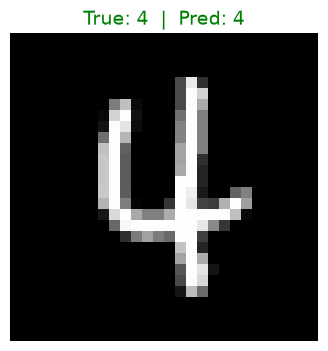

In [31]:
import matplotlib.pyplot as plt
import random

# 1. Chọn chỉ số ảnh
idx = random.randint(0, len(test_dataset) - 1)

# 2. Lấy ảnh và nhãn thật
image, true_label = test_dataset[idx]          # image: (1, 28, 28)

# 3. Đưa qua model để dự đoán
with torch.no_grad():
    input_tensor = image.unsqueeze(0).to(device)   # (1, 1, 28, 28)
    output = model(input_tensor)                   # (1, 10)
    pred_label = output.argmax(dim=1).item()

# 4. Hiển thị ảnh
plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(0).cpu().numpy(), cmap="gray")
color = "green" if pred_label == true_label else "red"
plt.title(f"True: {true_label}  |  Pred: {pred_label}",
            color=color, fontsize=14)
plt.axis("off")
plt.show()